# Error analysis of the margin model on 2022

Where does the margin-feature model (`xgboost_price_minus_wv.ipynb`, honest protocol, 2022 micro AUC 0.9786) still go wrong?
The model is retrained here with the same protocol so its 2022 predictions are available, then the errors are sliced by

1. unit and month
2. distance to the nearest ON/OFF transition and length of the ON/OFF run (does the model miss the start/stop dynamics?)
3. the price margin of the hour (are errors concentrated where price ≈ water value?)
4. hour of day
5. cross-unit calibration (micro AUC pools all units into one ranking, so systematic per-unit offsets matter)
6. the minimum-flow constraint on the river below Lio, the weakest unit
7. a cheap test: smoothing the predicted probabilities over neighbouring hours

Error measure per slice: mean squared error of the probability (Brier) and the share of the total squared error that the
slice carries. AUC is reported per slice only where both classes exist.

## Findings (2022, honest margin model, micro AUC 0.9786, Brier 0.0546)

1. **Two units carry a third of the error.** Lio_G1 (AUC 0.891, 19% of squared error) and Haukeli_G1 (0.919, 12.5%). Both are
   *over-predicted*: mean prediction 0.61 vs true ON share 0.55 for Lio, 0.23 vs 0.14 for Haukeli. The model thinks they
   should run more often than the optimiser does.
2. **Transitions dominate.** Hours within 2 h of a start/stop are 12% of the hours but 33% of the error; the first hour of a
   run has Brier 0.20 vs 0.017 for weeks with no change. Runs of ≤ 5 h are 4% of hours and 12% of the error.
   Smoothing the probabilities over neighbouring hours makes things *worse* (−0.0009 at 3 h), so the fix has to be
   features that describe the local price/margin context, not post-processing.
3. **Units running despite a deeply negative margin.** The margin < −40 EUR/MWh bin is half the hours with a 7% ON share,
   yet 42% of the error: units committed when price is far below the water value, i.e. forced running (minimum flow,
   spill avoidance, a full reservoir). The symmetric case (OFF despite margin > 40, ON share 91%) carries 16%.
4. **Worst months are April (0.941) and November (0.949)**, the spring flood and the autumn filling period, consistent with 3.
5. **Lio's minimum-flow constraint is active all year** (5, 8 or 14 m³/s), so a binary constraint flag cannot help; the
   *level* and the inflow/volume relative to it might.
6. **Cross-unit calibration is not the lever.** Macro AUC 0.972 vs micro 0.979; per-unit isotonic fitted on 2021 lowers
   the 2022 score (0.9772), the in-sample upper bound is only +0.004.

**Conclusion:** next features should describe (a) forced operation: fill fraction, inflow vs capacity, min-flow level and
margin to the min-volume constraint, especially for Lio and Haukeli; and (b) the local context around each hour:
rolling margin statistics over ±3/6/12 h and the number of positive-margin hours in the day.

### Shared code

Data loading, feature construction and the honest validation protocol. The same code is repeated at the top of every notebook so each one runs on its own.

In [ ]:
from pathlib import Path
from sklearn.metrics import roc_auc_score
import json
import numpy as np
import pandas as pd
import re
import time
import xgboost as xgb

# ---- formerly src/train_xgb_baseline.py ----
# XGBoost baseline for the SINTEF unit-commitment task.
#
# Script version of xgboost_baseline.ipynb so it can run headless on the GPU desktop.
#
# Validation protocol: rounds are chosen by early stopping on 2021 (training on cases before 2021);
# the reported score is then from a model trained on cases before 2022 and scored on 2022, so the
# reported year never influences a modelling decision. A one-week gap keeps overlapping cases apart.
#
#     py train_xgb_baseline.py --device cuda          # GPU
#     python train_xgb_baseline.py --device cpu       # laptop
#
# Outputs (in --out, default ./results):
#     submission_xgb_baseline.csv   Kaggle submission (test cases 2023-2024)
#     val_pred_2022.npy             hold-out probabilities, shape (365*168, 14)
#     metrics.json                  hold-out micro AUC, per-unit AUC, best iteration, timings
#     feature_importance.csv        gain per feature (summed over the 14 boosters)

H = 168
SEED = 42

def load(data_dir):
    data_dir = Path(data_dir)
    uc = pd.read_csv(
        data_dir / "Unit_commitment_decisions.csv", parse_dates=["starttime"]
    )
    price = (
        pd.read_csv(
            data_dir / "Historical_day_ahead_price_2015_2025.csv", parse_dates=["date"]
        )
        .set_index("date")["Day-ahead price (EUR/MWh)"]
        .resample("h")
        .mean()
    )
    inflow = pd.read_csv(
        data_dir / "Historical_inflow_1958_2025.csv", parse_dates=["date"]
    ).set_index("date")
    inflow = inflow[inflow.index >= "2014-12-01"].resample("h").mean()
    volume = pd.read_csv(
        data_dir / "Historical_volume_2015_2024.csv", parse_dates=["date"]
    ).set_index("date")
    water_value = pd.read_csv(
        data_dir / "Synthetic_water_value_2015_2024.csv", parse_dates=["date"]
    ).set_index("date")
    return uc, price, inflow, volume, water_value

class FeatureBuilder:
    def __init__(self, price, inflow, volume, water_value):
        self.price, self.inflow, self.volume, self.wv = (
            price,
            inflow,
            volume,
            water_value,
        )

    @staticmethod
    def window(hourly_df, starts, horizon=H):
        idx = hourly_df.index.get_indexer(starts)
        assert (idx >= 0).all(), (
            "some case start times are missing from the hourly series"
        )
        pos = idx[:, None] + np.arange(horizon)[None, :]
        return hourly_df.to_numpy(dtype=np.float32)[pos]

    def __call__(self, starts):
        starts = pd.DatetimeIndex(starts)
        if starts.tz is None:
            starts = starts.tz_localize("UTC")
        n = len(starts)
        P = self.window(self.price.to_frame(), starts)[:, :, 0]
        I = self.window(self.inflow, starts)
        V = self.volume.reindex(starts).to_numpy(dtype=np.float32)
        W = self.wv.reindex(starts).to_numpy(dtype=np.float32)
        W_end = self.wv.reindex(starts + pd.Timedelta(days=7)).to_numpy(
            dtype=np.float32
        )
        hours = pd.DatetimeIndex(
            (
                starts.values[:, None] + np.arange(H)[None, :] * np.timedelta64(1, "h")
            ).ravel()
        )
        rep = lambda a: np.repeat(a, H)

        f = pd.DataFrame(
            {
                "t": np.tile(np.arange(H), n),
                "hour": hours.hour,
                "dow": hours.dayofweek,
                "month": hours.month,
                "doy": hours.dayofyear,
                "price": P.ravel(),
                "price_week_mean": rep(P.mean(1)),
                "price_week_std": rep(P.std(1)),
                "price_week_min": rep(P.min(1)),
                "price_week_max": rep(P.max(1)),
            }
        )
        f["price_rel"] = f["price"] - f["price_week_mean"]
        f["price_rank"] = (P.argsort(1).argsort(1) / (H - 1)).ravel()
        f["price_day_mean"] = np.repeat(P.reshape(n, 7, 24).mean(2), 24, axis=1).ravel()
        f["price_prev"] = np.concatenate([P[:, :1], P[:, :-1]], axis=1).ravel()   # edge-padded, no wrap
        f["price_next"] = np.concatenate([P[:, 1:], P[:, -1:]], axis=1).ravel()
        for j, c in enumerate(self.inflow.columns):
            f[f"inflow_{c}"] = I[:, :, j].ravel()
        f["inflow_total"] = I.sum(2).ravel()
        for j, c in enumerate(self.volume.columns):
            f[f"vol_{c}"] = rep(V[:, j])
        for j, c in enumerate(self.wv.columns):
            f[f"wv_{c}"] = rep(W[:, j])
        for j, c in enumerate(self.wv.columns):
            f[f"wv_end_{c}"] = rep(W_end[:, j])
        return f

def split_masks(starts, val_year, gap_days=7):
    """Case-level masks. train: cases whose whole week ends before val_year (so no hour is shared with the
    validation cases); val: cases starting in val_year. Returned per case, use np.repeat(mask, H) for rows."""
    starts = pd.DatetimeIndex(starts)
    val_start = pd.Timestamp(f"{val_year}-01-01")
    train = np.asarray(starts < val_start - pd.Timedelta(days=gap_days - 1))
    val = np.asarray(starts.year == val_year)
    return train, val

def honest_fit(X, Y, starts, params, tune_year=2021, report_year=2022, device="cuda", verbose=False, max_rounds=3000):
    """Two-stage validation so the reported year is never used to make a modelling decision.

    stage 1: train on cases before tune_year, early-stop on tune_year  -> number of rounds
    stage 2: train on cases before report_year with that many rounds   -> score on report_year
    Returns a dict with n_rounds, tune_auc, report_auc, per-unit AUC, the stage-2 model and its predictions.
    """
    common = dict(tree_method="hist", device=device, random_state=SEED, **params)
    tr1, va1 = (np.repeat(m, H) for m in split_masks(starts, tune_year))
    m1 = xgb.XGBClassifier(n_estimators=max_rounds, eval_metric="auc", early_stopping_rounds=100, **common)
    m1.fit(X[tr1], Y[tr1], eval_set=[(X[va1], Y[va1])], verbose=verbose)
    n_rounds = int(m1.best_iteration) + 1
    tune_auc = roc_auc_score(Y[va1], m1.predict_proba(X[va1]), average="micro")

    tr2, va2 = (np.repeat(m, H) for m in split_masks(starts, report_year))
    m2 = xgb.XGBClassifier(n_estimators=n_rounds, **common).fit(X[tr2], Y[tr2])
    pred = m2.predict_proba(X[va2])
    report_auc = roc_auc_score(Y[va2], pred, average="micro")   # identical to kaggle_metric.score
    per_unit = [roc_auc_score(Y[va2][:, j], pred[:, j]) for j in range(Y.shape[1])]
    return dict(n_rounds=n_rounds, tune_auc=float(tune_auc), report_auc=float(report_auc),
                per_unit=per_unit, model=m2, pred=pred, val_mask=va2)

# ---- formerly src/features_margin.py ----
# Price-minus-water-value features (see xgboost_price_minus_wv.ipynb).
# plant -> reservoir directly upstream, from the connections in data/extended/Tokke_Vinje_topology.yaml
UPSTREAM = {
    "Hogga": "Bandak", "Tokke": "Vinjevatn", "Lio": "Byrtevatn", "Byrte": "Botnedalsvatn",
    "Vinje": "Vaamarvatn", "Haukeli": "Vatjern", "Songa": "Songavatn", "Kjela": "Foersvatn",
    "Vesle Kjela": "Kjelavatn",
}

def add_margin_features(f):
    f = f.copy()
    for plant, res in UPSTREAM.items():
        f[f"margin_{plant}"] = f["price"] - f[f"wv_{res}"]
        f[f"margin_end_{plant}"] = f["price"] - f[f"wv_end_{res}"]
        f[f"margin_end_wk_{plant}"] = f["price_week_mean"] - f[f"wv_end_{res}"]
    return f


In [1]:
# run from the repo root so that data/ and results/ resolve (notebooks live in notebooks/)
import os, sys
if os.path.basename(os.getcwd()) == "notebooks":
    os.chdir("..")

import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import xgboost as xgb
from scipy.ndimage import uniform_filter1d
from sklearn.metrics import roc_auc_score
from sklearn.isotonic import IsotonicRegression

SEED = 42
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.25, "figure.dpi": 110})
BLUE, GREY = "#2a78d6", "#9aa3ad"

def pick_device():
    try:
        xgb.XGBClassifier(n_estimators=1, device="cuda").fit(np.zeros((4, 1)), [0, 1, 0, 1]); return "cuda"
    except Exception:
        return "cpu"
DEVICE = pick_device(); print("device:", DEVICE)

device: cuda


## 1. Retrain the margin model (rounds on 2021, score on 2022) and keep its 2022 predictions

In [2]:
uc, price, inflow, volume, water_value = load("data/kernel")
sample = pd.read_csv("sample_submission.csv", nrows=1)
label_cols = [c for c in sample.columns if c != "Run No"]
units = list(dict.fromkeys(c.rsplit("_t", 1)[0].replace("result_committed_", "") for c in label_cols))
N_UNITS = len(units)
plants = [u.rsplit("_G", 1)[0] for u in units]

X = add_margin_features(FeatureBuilder(price, inflow, volume, water_value)(uc["starttime"]))
Y = uc[label_cols].to_numpy(dtype=np.int8).reshape(len(uc), N_UNITS, H).transpose(0, 2, 1).reshape(-1, N_UNITS)

params = dict(learning_rate=0.05, max_depth=6, subsample=0.8, colsample_bytree=0.8, min_child_weight=5)
t0 = time.time()
res = honest_fit(X, Y, uc["starttime"], params, tune_year=2021, report_year=2022, device=DEVICE)
print(f"rounds {res['n_rounds']}, 2022 micro AUC {res['report_auc']:.4f} ({time.time() - t0:.0f}s)")

va = res["val_mask"]
P = res["pred"].astype(np.float64); Yv = Y[va].astype(np.float64); Xv = X[va].reset_index(drop=True)
n_val = len(P) // H
P3, Y3 = P.reshape(n_val, H, N_UNITS), Yv.reshape(n_val, H, N_UNITS)          # (case, hour, unit)
val_starts = uc.loc[split_masks(uc["starttime"], 2022)[1], "starttime"].reset_index(drop=True)
np.save("results/val_pred_2022_margin.npy", P.astype(np.float32))
SE = (P - Yv) ** 2                                                          # squared error per cell
print(f"{n_val} cases, total Brier {SE.mean():.4f}, cells {SE.size}")

C:\Users\thoma\AppData\Local\Programs\Python\Python312\Lib\site-packages\xgboost\core.py:569: UserWarning: [10:44:31] WARNING: C:\actions-runner\_work\xgboost\xgboost\src\common\error_msg.cc:62: Falling back to prediction using DMatrix due to mismatched devices. This might lead to higher memory usage and slower performance. XGBoost is running on: cuda:0, while the input data is on: cpu.
Potential solutions:
- Use a data structure that matches the device ordinal in the booster.
- Set the device for booster before call to inplace_predict.

This warning will only be shown once.

  return func(**kwargs)


rounds 222, 2022 micro AUC 0.9786 (77s)
365 cases, total Brier 0.0546, cells 858480


## 2. By unit and by month

In [3]:
def micro_auc(y, p):
    y, p = np.asarray(y).ravel(), np.asarray(p).ravel()
    return roc_auc_score(y, p) if 0 < y.mean() < 1 else np.nan

by_unit = pd.DataFrame({
    "on_share": Yv.mean(0), "auc": [micro_auc(Yv[:, j], P[:, j]) for j in range(N_UNITS)],
    "brier": SE.mean(0), "share_of_error": SE.sum(0) / SE.sum(),
    "mean_pred": P.mean(0), "mean_true": Yv.mean(0),
}, index=units).sort_values("auc")
by_unit.round(3)

,on_share,auc,brier,share_of_error,mean_pred,mean_true
Lio_G1,0.550,0.891,0.147,0.192,0.611,0.550
Haukeli_G1,0.141,0.919,0.095,0.125,0.229,0.141
Vinje_G3,0.192,0.968,0.058,0.076,0.214,0.192
Hogga_G1,0.387,0.973,0.063,0.083,0.406,0.387
Kjela_G1,0.453,0.977,0.051,0.067,0.428,0.453
Vinje_G2,0.297,0.977,0.056,0.073,0.296,0.297
Tokke_G4,0.373,0.982,0.054,0.071,0.351,0.373
Vinje_G1,0.344,0.983,0.053,0.069,0.324,0.344
Vesle Kjela_G1,0.306,0.983,0.031,0.041,0.295,0.306
Tokke_G2,0.357,0.984,0.050,0.066,0.351,0.357


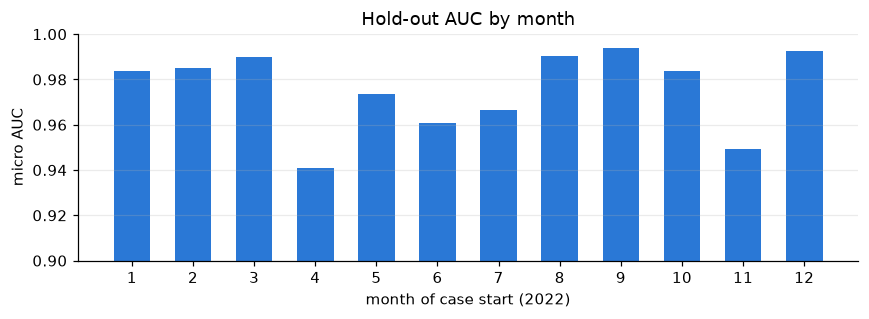

,cases,on_share,micro_auc,brier,median_price
1,31,0.343,0.984,0.054,136.625000
2,28,0.247,0.985,0.068,118.510002
3,31,0.271,0.990,0.031,188.720001
4,30,0.412,0.941,0.103,185.630005
5,31,0.438,0.973,0.066,172.029999
6,30,0.185,0.961,0.054,186.919998
7,31,0.121,0.966,0.046,276.989990
8,31,0.095,0.991,0.022,450.100006
9,30,0.320,0.994,0.029,340.559998
10,31,0.537,0.984,0.051,116.800003


In [4]:
month = val_starts.dt.month.to_numpy()
by_month = pd.DataFrame({
    "cases": [int((month == m).sum()) for m in range(1, 13)],
    "on_share": [Y3[month == m].mean() for m in range(1, 13)],
    "micro_auc": [micro_auc(Y3[month == m], P3[month == m]) for m in range(1, 13)],
    "brier": [SE.reshape(n_val, H, N_UNITS)[month == m].mean() for m in range(1, 13)],
    "median_price": [np.median(Xv["price"].to_numpy().reshape(n_val, H)[month == m]) for m in range(1, 13)],
}, index=range(1, 13))
fig, ax = plt.subplots(figsize=(8, 3))
ax.bar(by_month.index, by_month["micro_auc"], color=BLUE, width=0.6)
ax.set_ylim(0.9, 1.0); ax.set_xticks(range(1, 13)); ax.set_xlabel("month of case start (2022)"); ax.set_ylabel("micro AUC")
ax.set_title("Hold-out AUC by month"); ax.grid(axis="x", visible=False)
plt.tight_layout(); plt.show()
by_month.round(3)

## 3. Start/stop dynamics: distance to the nearest transition and run length

For every (case, unit) sequence of 168 labels, each hour gets (a) the distance in hours to the nearest point where the
true label changes, and (b) the length of the constant ON/OFF run it belongs to.

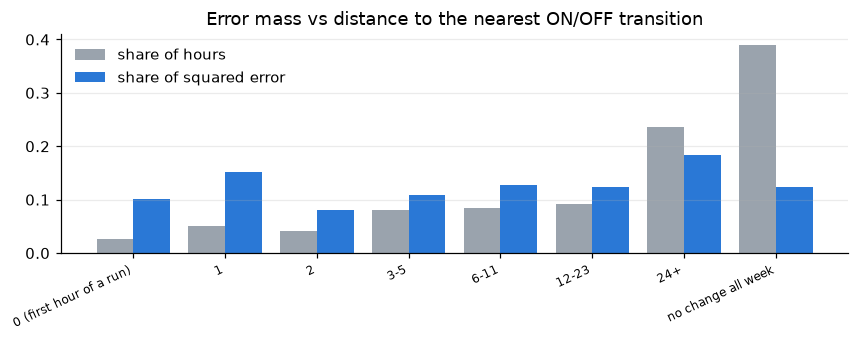

,hours,brier,share_of_error,share_of_hours
0 (first hour of a run),23360,0.202,0.101,0.027
1,43016,0.165,0.152,0.050
2,35505,0.106,0.080,0.041
3-5,68722,0.074,0.109,0.080
6-11,71712,0.083,0.127,0.084
12-23,78204,0.074,0.124,0.091
24+,202801,0.042,0.183,0.236
no change all week,335160,0.017,0.124,0.390


In [5]:
dist = np.full(Y3.shape, 999, dtype=np.int32)
runlen = np.zeros(Y3.shape, dtype=np.int32)
for i in range(n_val):
    for j in range(N_UNITS):
        y = Y3[i, :, j]
        change = np.flatnonzero(np.diff(y) != 0) + 1          # index of first hour of each new run
        bounds = np.concatenate([[0], change, [H]])
        for a, b in zip(bounds[:-1], bounds[1:]):
            runlen[i, a:b, j] = b - a
        if len(change):
            t = np.arange(H)
            d_prev = t - np.concatenate([[ -10**6 ], change])[np.searchsorted(change, t, side="right")]
            d_next = np.concatenate([change, [10**6]])[np.searchsorted(change, t, side="right")] - t
            dist[i, :, j] = np.minimum(np.abs(d_prev), d_next)
dist_bins = pd.cut(dist.ravel(), [-1, 0, 1, 2, 5, 11, 23, 998, 10**6],
                   labels=["0 (first hour of a run)", "1", "2", "3-5", "6-11", "12-23", "24+", "no change all week"])
se3 = SE.reshape(n_val, H, N_UNITS)
by_dist = pd.DataFrame({"hours": pd.Series(dist_bins).value_counts(sort=False),
                        "brier": pd.Series(se3.ravel()).groupby(dist_bins, observed=True).mean(),
                        "share_of_error": pd.Series(se3.ravel()).groupby(dist_bins, observed=True).sum() / SE.sum()})
by_dist["share_of_hours"] = by_dist["hours"] / by_dist["hours"].sum()
fig, ax = plt.subplots(figsize=(8, 3.2))
x = np.arange(len(by_dist))
ax.bar(x - 0.2, by_dist["share_of_hours"], width=0.4, color=GREY, label="share of hours")
ax.bar(x + 0.2, by_dist["share_of_error"], width=0.4, color=BLUE, label="share of squared error")
ax.set_xticks(x); ax.set_xticklabels(by_dist.index, rotation=25, ha="right", fontsize=8); ax.legend(frameon=False)
ax.set_title("Error mass vs distance to the nearest ON/OFF transition"); ax.grid(axis="x", visible=False)
plt.tight_layout(); plt.show()
by_dist.round(3)

In [6]:
run_bins = pd.cut(runlen.ravel(), [0, 2, 5, 11, 23, 47, 167, 168],
                  labels=["1-2 h", "3-5 h", "6-11 h", "12-23 h", "24-47 h", "48-167 h", "whole week"])
state = np.where(Y3.ravel() == 1, "ON run", "OFF run")
by_run = (pd.DataFrame({"run": run_bins, "state": state, "se": se3.ravel()})
          .groupby(["state", "run"], observed=True)["se"].agg(hours="size", brier="mean", sum_se="sum"))
by_run["share_of_error"] = by_run["sum_se"] / SE.sum()
by_run["share_of_hours"] = by_run["hours"] / by_run["hours"].sum()
by_run.drop(columns="sum_se").round(3)

hours  brier  share_of_error  share_of_hours
state   run                                                      
OFF run 1-2 h         1684  0.235           0.008           0.002
        3-5 h        14033  0.185           0.055           0.016
        6-11 h       31524  0.106           0.071           0.037
        12-23 h      38469  0.085           0.070           0.045
        24-47 h      37575  0.073           0.058           0.044
        48-167 h    187338  0.044           0.175           0.218
        whole week  255528  0.017           0.091           0.298
ON run  1-2 h         3017  0.216           0.014           0.004
        3-5 h        12744  0.171           0.047           0.015
        6-11 h       22360  0.141           0.067           0.026
        12-23 h      44157  0.091           0.086           0.051
        24-47 h      32382  0.104           0.072           0.038
        48-167 h     98037  0.073           0.152           0.114
        whole week   79632  0.020           0.033           0.093

## 4. Error vs the price margin of the hour (price − end-of-week water value of the plant's reservoir)

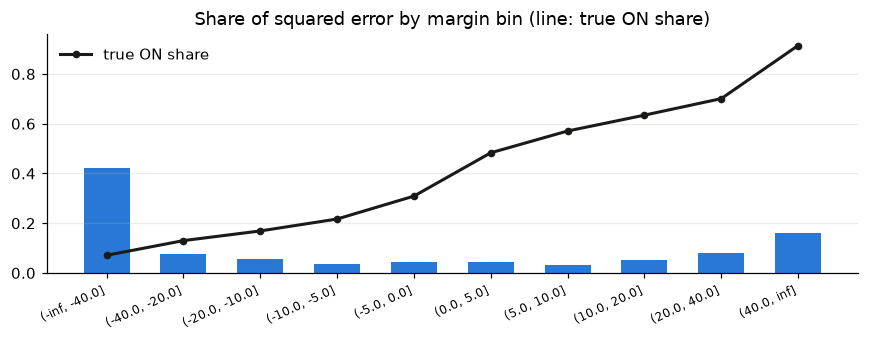

,hours,on_share,mean_pred,brier,share_of_error
"(-inf, -40.0]",438631,0.071,0.092,0.045,0.422
"(-40.0, -20.0]",58581,0.130,0.118,0.061,0.077
"(-20.0, -10.0]",32927,0.169,0.149,0.077,0.054
"(-10.0, -5.0]",16170,0.217,0.191,0.105,0.036
"(-5.0, 0.0]",15113,0.309,0.299,0.141,0.045
"(0.0, 5.0]",14944,0.483,0.535,0.134,0.043
"(5.0, 10.0]",14513,0.571,0.623,0.101,0.031
"(10.0, 20.0]",31019,0.634,0.676,0.079,0.052
"(20.0, 40.0]",54534,0.701,0.738,0.069,0.080
"(40.0, inf]",182048,0.914,0.880,0.041,0.160


In [7]:
M3 = np.stack([Xv[f"margin_end_{pl}"].to_numpy().reshape(n_val, H) for pl in plants], axis=2)
m_bins = pd.cut(M3.ravel(), [-np.inf, -40, -20, -10, -5, 0, 5, 10, 20, 40, np.inf])
by_margin = pd.DataFrame({"hours": pd.Series(m_bins).value_counts(sort=False),
                          "on_share": pd.Series(Y3.ravel()).groupby(m_bins, observed=True).mean(),
                          "mean_pred": pd.Series(P3.ravel()).groupby(m_bins, observed=True).mean(),
                          "brier": pd.Series(se3.ravel()).groupby(m_bins, observed=True).mean(),
                          "share_of_error": pd.Series(se3.ravel()).groupby(m_bins, observed=True).sum() / SE.sum()})
fig, ax = plt.subplots(figsize=(8, 3.2))
x = np.arange(len(by_margin))
ax.bar(x, by_margin["share_of_error"], color=BLUE, width=0.6)
ax.plot(x, by_margin["on_share"], color="#1a1a19", lw=2, marker="o", ms=4, label="true ON share")
ax.set_xticks(x); ax.set_xticklabels([str(i) for i in by_margin.index], rotation=25, ha="right", fontsize=8)
ax.set_title("Share of squared error by margin bin (line: true ON share)"); ax.legend(frameon=False); ax.grid(axis="x", visible=False)
plt.tight_layout(); plt.show()
by_margin.round(3)

## 5. Hour of day

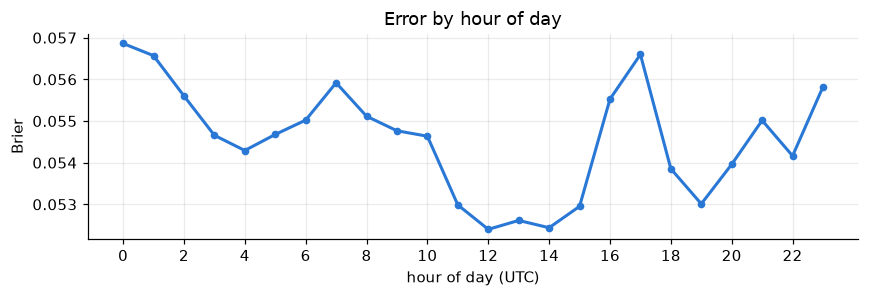

In [8]:
hod = np.tile(np.arange(H) % 24, n_val)
by_hour = pd.DataFrame({"brier": [se3.reshape(n_val * H, N_UNITS)[hod == h].mean() for h in range(24)],
                        "on_share": [Y3.reshape(n_val * H, N_UNITS)[hod == h].mean() for h in range(24)]}, index=range(24))
fig, ax = plt.subplots(figsize=(8, 2.8))
ax.plot(by_hour.index, by_hour["brier"], color=BLUE, lw=2, marker="o", ms=4)
ax.set_xlabel("hour of day (UTC)"); ax.set_ylabel("Brier"); ax.set_title("Error by hour of day"); ax.set_xticks(range(0, 24, 2))
plt.tight_layout(); plt.show()

## 6. Cross-unit calibration and the micro average

Micro AUC ranks every (unit, hour) cell in one pool. If one unit's probabilities are systematically too high, its OFF hours
outrank other units' ON hours. Two diagnostics: the macro (per-unit mean) AUC, which ignores cross-unit ordering, and
micro AUC after an isotonic recalibration per unit. Calibrating on 2022 itself is an optimistic upper bound; calibrating
on the 2021 tuning predictions (what one could really do) is also computed.

In [9]:
macro = np.mean([micro_auc(Yv[:, j], P[:, j]) for j in range(N_UNITS)])
P_iso_self = np.column_stack([IsotonicRegression(out_of_bounds="clip").fit(P[:, j], Yv[:, j]).predict(P[:, j]) for j in range(N_UNITS)])
print(f"micro AUC {res['report_auc']:.4f} | macro (mean per-unit) AUC {macro:.4f} | micro after per-unit isotonic on 2022 (upper bound) {micro_auc(Yv, P_iso_self):.4f}")

# the realistic version: fit the stage-1 model's 2021 predictions -> isotonic per unit -> apply to 2022
tr1, va1 = (np.repeat(m, H) for m in split_masks(uc["starttime"], 2021))
m1 = xgb.XGBClassifier(n_estimators=res["n_rounds"], tree_method="hist", device=DEVICE, random_state=SEED, **params).fit(X[tr1], Y[tr1])
P21, Y21 = m1.predict_proba(X[va1]), Y[va1]
P_iso_2021 = np.column_stack([IsotonicRegression(out_of_bounds="clip").fit(P21[:, j], Y21[:, j]).predict(P[:, j]) for j in range(N_UNITS)])
print(f"micro after per-unit isotonic fitted on 2021 (realistic): {micro_auc(Yv, P_iso_2021):.4f}")
pd.DataFrame({"mean_pred": P.mean(0), "mean_true": Yv.mean(0), "offset": P.mean(0) - Yv.mean(0)}, index=units).sort_values("offset").round(3)

micro AUC 0.9786 | macro (mean per-unit) AUC 0.9718 | micro after per-unit isotonic on 2022 (upper bound) 0.9824


micro after per-unit isotonic fitted on 2021 (realistic): 0.9772


,mean_pred,mean_true,offset
Kjela_G1,0.428,0.453,-0.025
Tokke_G4,0.351,0.373,-0.022
Vinje_G1,0.324,0.344,-0.019
Vesle Kjela_G1,0.295,0.306,-0.011
Byrte_G1,0.375,0.383,-0.009
Tokke_G2,0.351,0.357,-0.006
Tokke_G1,0.455,0.457,-0.002
Vinje_G2,0.296,0.297,-0.001
Songa_G1,0.116,0.117,-0.001
Tokke_G3,0.415,0.411,0.004


## 7. Lio and the minimum-flow constraint on the river below it

In [10]:
minflow = pd.read_csv("data/extended/Constraint_min_flow.csv", parse_dates=["date"]).set_index("date").resample("h").mean()
starts_utc = pd.DatetimeIndex(val_starts).tz_localize("UTC")
idx = minflow.index.get_indexer(starts_utc)
MF = minflow["r_Vest_Vassdraget"].to_numpy()[idx[:, None] + np.arange(H)[None, :]]       # (case, hour)
j_lio = units.index("Lio_G1")
lio = pd.DataFrame({"min_flow": MF.ravel(), "y": Y3[:, :, j_lio].ravel(), "p": P3[:, :, j_lio].ravel(), "se": se3[:, :, j_lio].ravel()})
lio["constraint"] = np.where(lio["min_flow"] > 0, "min flow > 0", "no min flow")
summary = lio.groupby("constraint").agg(hours=("y", "size"), on_share=("y", "mean"), mean_pred=("p", "mean"), brier=("se", "mean"))
summary["auc"] = [micro_auc(g["y"], g["p"]) for _, g in lio.groupby("constraint")]
print("Lio_G1 overall AUC:", round(by_unit.loc["Lio_G1", "auc"], 3), "| distinct min-flow levels:", sorted(lio["min_flow"].unique()))
summary.round(3)

Lio_G1 overall AUC: 0.891 | distinct min-flow levels: [np.float64(5.0), np.float64(8.0), np.float64(14.0)]


,hours,on_share,mean_pred,brier,auc
constraint,,,,,
min flow > 0,61320,0.55,0.611,0.147,0.891


## 8. Cheap test: smoothing the probabilities over neighbouring hours

In [11]:
rows = []
for k in [1, 3, 5, 7, 9]:
    Ps = uniform_filter1d(P3, size=k, axis=1, mode="nearest") if k > 1 else P3
    rows.append({"window_hours": k, "micro_auc": micro_auc(Y3, Ps), "brier": ((Ps - Y3) ** 2).mean()})
smooth = pd.DataFrame(rows).set_index("window_hours")
smooth["auc_gain"] = smooth["micro_auc"] - smooth.loc[1, "micro_auc"]
smooth.round(4)

,micro_auc,brier,auc_gain
window_hours,,,
1,0.9786,0.0546,0.0000
3,0.9777,0.0550,-0.0009
5,0.9761,0.0569,-0.0025
7,0.9740,0.0595,-0.0046
9,0.9715,0.0626,-0.0071


## 9. Summary numbers

In [12]:
print(f"2022 micro AUC {res['report_auc']:.4f}, Brier {SE.mean():.4f}")
print("worst units:", by_unit.head(3)["auc"].round(3).to_dict())
print("worst months:", by_month["micro_auc"].nsmallest(3).round(3).to_dict())
print(f"error share within 2 h of a transition: {by_dist['share_of_error'].iloc[:3].sum():.2f}  (share of hours {by_dist['share_of_hours'].iloc[:3].sum():.2f})")
short = by_run.index.get_level_values("run").isin(["1-2 h", "3-5 h"])
print(f"error share in runs <= 5 h: {by_run.loc[short, 'share_of_error'].sum():.2f}  (share of hours {by_run.loc[short, 'share_of_hours'].sum():.2f})")
print(f"error share with |margin| <= 10: {by_margin.loc[[i for i in by_margin.index if i.left >= -10 and i.right <= 10], 'share_of_error'].sum():.2f}")
print(f"best smoothing window: {smooth['micro_auc'].idxmax()} h, gain {smooth['auc_gain'].max():+.4f}")

2022 micro AUC 0.9786, Brier 0.0546
worst units: {'Lio_G1': 0.891, 'Haukeli_G1': 0.919, 'Vinje_G3': 0.968}
worst months: {4: 0.941, 11: 0.949, 6: 0.961}
error share within 2 h of a transition: 0.33  (share of hours 0.12)
error share in runs <= 5 h: 0.12  (share of hours 0.04)
error share with |margin| <= 10: 0.16
best smoothing window: 1 h, gain +0.0000
